<a href="https://colab.research.google.com/github/Priyadharshini-7431/SentimentScopeModel/blob/main/SentimentScopeModel1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SentimentScope: Sentiment Analysis Using Transformers

# Import Libraries

In [35]:
!pip install -q torch transformers pandas numpy matplotlib scikit-learn

In [36]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# Dataset Loading

In [37]:
import os

if not os.path.exists("/content/aclImdb"):
    if not os.path.exists("/content/aclImdb_v1.tar.gz"):
        !wget -q https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz -O /content/aclImdb_v1.tar.gz

    !tar -xzf /content/aclImdb_v1.tar.gz -C /content

print("Train positive exists:",
      os.path.isdir("/content/aclImdb/train/pos"))
print("Train negative exists:",
      os.path.isdir("/content/aclImdb/train/neg"))
print("Test positive exists:",
      os.path.isdir("/content/aclImdb/test/pos"))
print("Test negative exists:",
      os.path.isdir("/content/aclImdb/test/neg"))

Train positive exists: True
Train negative exists: True
Test positive exists: True
Test negative exists: True


# Exploratory Data Analysis (EDA)

In [38]:
train_pos_path = "/content/aclImdb/train/pos"
train_neg_path = "/content/aclImdb/train/neg"
test_pos_path = "/content/aclImdb/test/pos"
test_neg_path = "/content/aclImdb/test/neg"


def load_dataset(folder):
    reviews = []

    for filename in sorted(os.listdir(folder)):
        if filename.endswith(".txt"):
            file_path = os.path.join(folder, filename)

            with open(file_path, "r", encoding="utf-8") as file:
                reviews.append(file.read().strip())

    return reviews


train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

print("Train positive:", len(train_pos))
print("Train negative:", len(train_neg))
print("Test positive:", len(test_pos))
print("Test negative:", len(test_neg))

Train positive: 12500
Train negative: 12500
Test positive: 12500
Test negative: 12500


# Data Preprocessing

In [39]:
train_df = pd.DataFrame({
    "review": train_pos + train_neg,
    "label": [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    "review": test_pos + test_neg,
    "label": [1] * len(test_pos) + [0] * len(test_neg)
})

assert train_df.shape == (25000, 2)
assert test_df.shape == (25000, 2)

print(train_df.head())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1
Train shape: (25000, 2)
Test shape: (25000, 2)


Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

Label statistics:
label
1    12500
0    12500
Name: count, dtype: int64

Review length statistics:
count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: review_length, dtype: float64


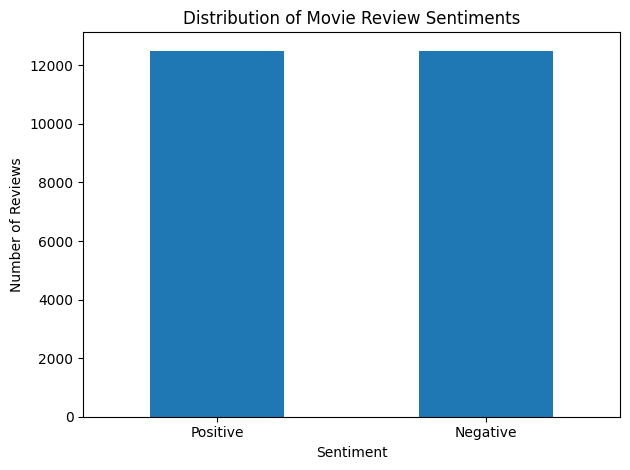

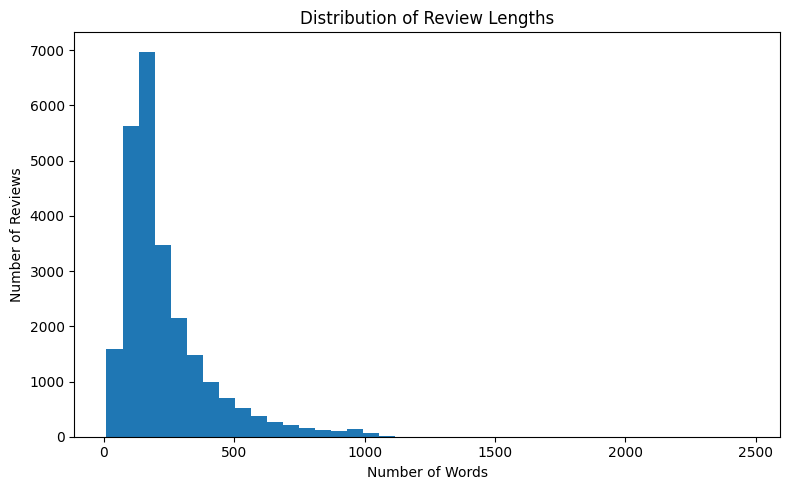


Sample positive review:
Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's satire is much closer to reality than is "Teachers". The scramble to survive financially, the insightful students who can see right through their pathetic teachers' pomp, the pettiness of the whole situation, all remind me of the schools I knew and their students. When I saw the episode in which a s

Sample negative review:
Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of absurd comedy. A formal orchestra audience is turned into an insane, violent mob by the crazy chantings of it's singers. Unfortunately it stays absurd the WHOLE time with no general narrative eventually making it just too off putting. Even those from the era should be turned off. The cryptic dialogue would make Shakespeare seem easy

In [40]:
print("Training dataset information:")
train_df.info()

print("\nLabel statistics:")
print(train_df["label"].value_counts())

print("\nReview length statistics:")
train_df["review_length"] = train_df["review"].str.split().str.len()
print(train_df["review_length"].describe())

# Visualization 1: Label distribution
label_counts = train_df["label"].map({
    0: "Negative",
    1: "Positive"
}).value_counts()

label_counts.plot(kind="bar")
plt.title("Distribution of Movie Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visualization 2: Review length distribution
plt.figure(figsize=(8, 5))
plt.hist(train_df["review_length"], bins=40)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

print("\nSample positive review:")
print(train_df[train_df["label"] == 1]["review"].iloc[0][:500])

print("\nSample negative review:")
print(train_df[train_df["label"] == 0]["review"].iloc[0][:500])

In [41]:
train_size = int(0.9 * len(train_df))

shuffled_df = train_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

train_data = shuffled_df.iloc[:train_size].copy()
val_data = shuffled_df.iloc[train_size:].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))
print("Test rows:", len(test_df))

Training rows: 22500
Validation rows: 2500
Test rows: 25000


# Dataset and DataLoaders

In [42]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

MAX_LENGTH = 128

sample_texts = train_data["review"].sample(
    3, random_state=42
).tolist()

tokenized_samples = tokenizer(
    sample_texts,
    truncation=True,
    padding="max_length",
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print("Tokenized input shape:", tokenized_samples["input_ids"].shape)

Tokenized input shape: torch.Size([3, 128])


In [43]:
MAX_LENGTH = 128

class IMDBDataset(Dataset):
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        review = str(self.data.iloc[idx]["review"])
        label = int(self.data.iloc[idx]["label"])

        encoded = self.tokenizer(
            review,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        input_ids = encoded["input_ids"].squeeze(0)

        return input_ids, label

In [44]:
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

assert len(train_dataset) == 22500
assert len(val_dataset) == 2500
assert len(test_dataset) == 25000

input_ids, label = train_dataset[0]

assert isinstance(input_ids, torch.Tensor)
assert isinstance(label, (int, np.integer))
assert input_ids.shape[0] == MAX_LENGTH

print("Dataset and DataLoader checks passed!")
print("Input shape:", input_ids.shape)
print("Sample label:", label)

Dataset and DataLoader checks passed!
Input shape: torch.Size([128])
Sample label: 1


In [45]:
config = {
    "vocabulary_size": tokenizer.vocab_size,
    "num_classes": 2,
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,
    "dropout_rate": 0.1,
    "use_bias": True
}

# Transformer Architecture

In [46]:

import torch
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.Q_weights = nn.Linear(
            config["d_embed"],
            config["head_size"],
            bias=config["use_bias"]
        )

        self.K_weights = nn.Linear(
            config["d_embed"],
            config["head_size"],
            bias=config["use_bias"]
        )

        self.V_weights = nn.Linear(
            config["d_embed"],
            config["head_size"],
            bias=config["use_bias"]
        )

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(
            torch.ones(
                config["context_size"],
                config["context_size"]
            )
        )

        self.register_buffer(
            "casual_attention_mask",
            casual_attention_mask
        )

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape

        Q = self.Q_weights(input)
        K = self.K_weights(input)
        V = self.V_weights(input)

        attention_scores = Q @ K.transpose(1, 2)

        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float("-inf")
        )

        attention_scores = attention_scores / math.sqrt(K.shape[-1])

        attention_scores = torch.softmax(
            attention_scores, dim=-1
        )

        attention_scores = self.dropout(attention_scores)

        output = attention_scores @ V

        return output

In [47]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.heads = nn.ModuleList([
            AttentionHead(config)
            for _ in range(config["heads_num"])
        ])

        self.linear = nn.Linear(
            config["heads_num"] * config["head_size"],
            config["d_embed"]
        )

        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)
        x = self.linear(x)
        x = self.dropout(x)
        return x

In [48]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

In [49]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])
        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input + self.multi_head(self.layer_norm_1(input))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

# DemoGPT Model

In [50]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.token_embedding_layer = nn.Embedding(
            config["vocabulary_size"],
            config["d_embed"]
        )

        self.positional_embedding_layer = nn.Embedding(
            config["context_size"],
            config["d_embed"]
        )

        blocks = [
            Block(config)
            for _ in range(config["layers_num"])
        ]

        self.layers = nn.Sequential(*blocks)
        self.layer_norm = nn.LayerNorm(config["d_embed"])

        # Classification output layer
        self.classification_head = nn.Linear(
            config["d_embed"],
            config["num_classes"],
            bias=False
        )

    def forward(self, token_ids):
        batch_size, tokens_num = token_ids.shape

        x = self.token_embedding_layer(token_ids)

        positions = torch.arange(
            tokens_num,
            device=token_ids.device
        )

        pos_embed = self.positional_embedding_layer(positions)
        x = x + pos_embed.unsqueeze(0)

        x = self.layers(x)
        x = self.layer_norm(x)

        # Mean pooling: (batch, sequence, embedding)
        # becomes (batch, embedding)
        x = torch.mean(x, dim=1)

        # Output logits: (batch, 2)
        logits = self.classification_head(x)

        return logits

In [51]:
demo_gpt = DemoGPT(config).to(device)

dummy_token_ids = torch.randint(
    0,
    config["vocabulary_size"],
    (BATCH_SIZE, config["context_size"]),
    device=device
)

with torch.no_grad():
    logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)

assert logits.shape == (BATCH_SIZE, config["num_classes"])

print("DemoGPT shape assertions passed!")

DemoGPT output shape: torch.Size([32, 2])
DemoGPT shape assertions passed!


# Model Testing

In [52]:
def calculate_accuracy(model, data_loader, device):
    model.eval()

    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids)
            predictions = torch.argmax(logits, dim=1)

            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    accuracy = (total_correct / total_samples) * 100
    return accuracy

In [53]:
model = DemoGPT(config).to(device)

validation_accuracy = calculate_accuracy(
    model,
    val_loader,
    device
)

print(f"Initial Validation Accuracy: {validation_accuracy:.2f}%")

Initial Validation Accuracy: 50.52%


In [54]:
EPOCHS = 3
LEARNING_RATE = 3e-4

model = DemoGPT(config).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

history = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for step, (input_ids, labels) in enumerate(train_loader):
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # 1. Forward pass
        logits = model(input_ids)

        # 2. Calculate loss
        loss = criterion(logits, labels)

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Backward pass
        loss.backward()

        # 5. Update model weights
        optimizer.step()

        running_loss += loss.item()

        if (step + 1) % 100 == 0:
            avg_loss = running_loss / 100

            print(
                f"Epoch [{epoch + 1}/{EPOCHS}], "
                f"Step [{step + 1}/{len(train_loader)}], "
                f"Loss: {avg_loss:.4f}"
            )

            running_loss = 0.0

    val_accuracy = calculate_accuracy(
        model,
        val_loader,
        device
    )

    history.append({
        "epoch": epoch + 1,
        "validation_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch + 1} - "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

print("Training completed!")
print(pd.DataFrame(history))

Epoch [1/3], Step [100/704], Loss: 0.6996
Epoch [1/3], Step [200/704], Loss: 0.6721
Epoch [1/3], Step [300/704], Loss: 0.6415
Epoch [1/3], Step [400/704], Loss: 0.6127
Epoch [1/3], Step [500/704], Loss: 0.5810
Epoch [1/3], Step [600/704], Loss: 0.5784
Epoch [1/3], Step [700/704], Loss: 0.5506
Epoch 1 - Validation Accuracy: 71.52%
Epoch [2/3], Step [100/704], Loss: 0.5026
Epoch [2/3], Step [200/704], Loss: 0.5001
Epoch [2/3], Step [300/704], Loss: 0.4873
Epoch [2/3], Step [400/704], Loss: 0.5040
Epoch [2/3], Step [500/704], Loss: 0.4819
Epoch [2/3], Step [600/704], Loss: 0.4818
Epoch [2/3], Step [700/704], Loss: 0.4753
Epoch 2 - Validation Accuracy: 77.40%
Epoch [3/3], Step [100/704], Loss: 0.4178
Epoch [3/3], Step [200/704], Loss: 0.4360
Epoch [3/3], Step [300/704], Loss: 0.4275
Epoch [3/3], Step [400/704], Loss: 0.4324
Epoch [3/3], Step [500/704], Loss: 0.4250
Epoch [3/3], Step [600/704], Loss: 0.4015
Epoch [3/3], Step [700/704], Loss: 0.4147
Epoch 3 - Validation Accuracy: 80.16%
Trai

# Results and Visualization

In [55]:
test_accuracy = calculate_accuracy(
    model,
    test_loader,
    device
)

print(f"Final Test Accuracy: {test_accuracy:.2f}%")

if test_accuracy > 75:
    print("Project accuracy target achieved!")
else:
    print("Accuracy is below 75%. Further training or tuning is needed.")

Final Test Accuracy: 76.72%
Project accuracy target achieved!


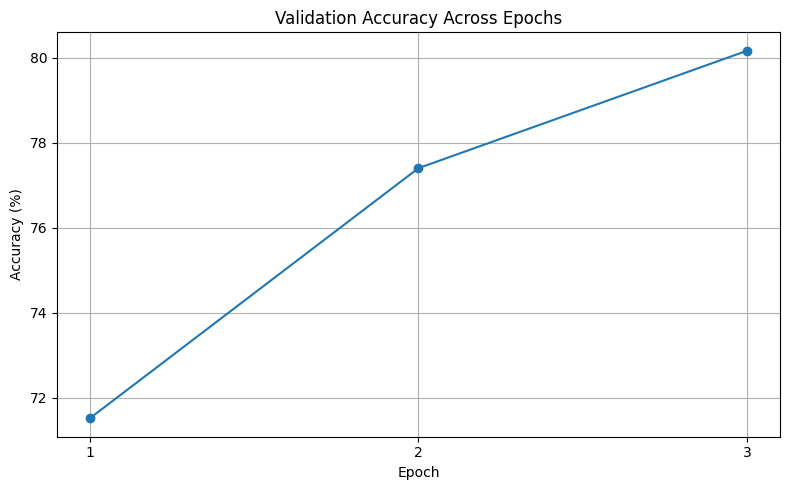

In [57]:
history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["validation_accuracy"],
    marker="o"
)

plt.title("Validation Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(history_df["epoch"])
plt.grid(True)
plt.tight_layout()
plt.show()

# Save Model

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import torch

save_dir = "/content/drive/MyDrive/SentimentScope_model"
os.makedirs(save_dir, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "config": config,
        "test_accuracy": test_accuracy
    },
    os.path.join(save_dir, "DemoGPT_checkpoint.pt")
)

print("Model checkpoint saved to:",save_dir)

Model checkpoint saved to: /content/drive/MyDrive/SentimentScope_model
